<center><h1>Ngo_Jesse_HW5</h1></center>

Name: Jesse Ngo
<br>
Github Username: hjngo
<br>
USC ID: 4722249405

In [1]:
# Imports
import re, textwrap, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text, _tree
from sklearn.model_selection import (KFold, RepeatedStratifiedKFold, GridSearchCV,
                                     cross_val_score)
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.metrics import mean_squared_error

warnings.filterwarnings("ignore", category=FutureWarning)
RS = 552   # random state
dataPath = Path("..") / "data"
assert dataPath.exists(), f"Run the notebook from its own folder (cwd is {Path.cwd()})"

## 1. Decision Trees as Interpretable Models

In [2]:
# Question 1a
# diagnosis.data: UTF-16, tab-separated, comma decimals ("35,5")
FEATURES = ["temperature", "nausea", "lumbar_pain", "urine_pushing",
            "micturition_pains", "burning_urethra"]
LABELS = ["inflammation", "nephritis"]
acute = pd.read_csv(dataPath / "diagnosis.data", encoding="utf-16", sep="\t",
                    header=None, decimal=",", names=FEATURES + LABELS)
yes_no = FEATURES[1:] + LABELS
acute[yes_no] = (acute[yes_no].apply(lambda c: c.str.strip()) == "yes").astype(int)
# print(acute.shape)

Class counts: {'00': 30, '01': 31, '10': 40, '11': 19}
Depth 4, 6 leaves, training accuracy 1.000


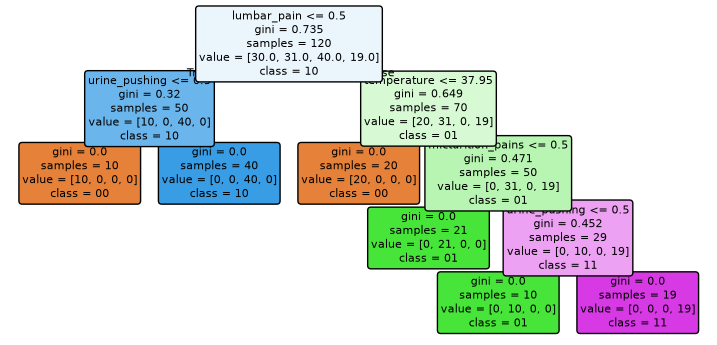

In [3]:
# Question 1b
# Footnote 1 -> label powerset: each (inflammation, nephritis) combo becomes one class.
# Only 2 labels = 4 classes, all present, and one tree captures how the two diseases
# co-occur. Binary relevance = 2 independent trees that ignore that -> powerset fits.
X1 = acute[FEATURES]
y1 = acute["inflammation"].astype(str) + acute["nephritis"].astype(str)  # e.g. "10"
print("Class counts:", y1.value_counts().sort_index().to_dict())

# no depth limit: grows until every leaf is pure (gini = 0)
tree_full = DecisionTreeClassifier(random_state=RS).fit(X1, y1)
print(f"Depth {tree_full.get_depth()}, {tree_full.get_n_leaves()} leaves, "
      f"training accuracy {tree_full.score(X1, y1):.3f}")

fig, ax = plt.subplots(figsize=(9, 4.2))
plot_tree(tree_full, feature_names=FEATURES, class_names=list(tree_full.classes_),
          filled=True, rounded=True, fontsize=8, ax=ax)
plt.show()

In [4]:
# Question 1c
# Footnote 2 (KDnuggets) idea: every root -> leaf path is one rule. The conditions along
# the path are ANDed together and the leaf's majority class is the THEN part.
CLASS_NAMES = {"00": "neither", "10": "inflammation only", "01": "nephritis only",
               "11": "both"}

def get_rules(tree, node=0, conds=()):
    t = tree.tree_
    if t.feature[node] == _tree.TREE_UNDEFINED:          # leaf -> one rule
        cls = tree.classes_[np.argmax(t.value[node])]
        return [(conds, cls, int(t.n_node_samples[node]))]
    f, thr = FEATURES[t.feature[node]], t.threshold[node]
    # binary symptoms split at 0.5, so "<= 0.5" really means "= no"
    left, right = ((f"{f} <= {thr:.2f}", f"{f} > {thr:.2f}") if f == "temperature"
                   else (f"{f} = no", f"{f} = yes"))
    return (get_rules(tree, t.children_left[node], conds + (left,)) +
            get_rules(tree, t.children_right[node], conds + (right,)))

for i, (conds, cls, n) in enumerate(get_rules(tree_full), 1):
    print(f"R{i}: IF {' AND '.join(conds)}")
    print(f"    THEN {cls} ({CLASS_NAMES[cls]}) [{n} patients]")

R1: IF lumbar_pain = no AND urine_pushing = no
    THEN 00 (neither) [10 patients]
R2: IF lumbar_pain = no AND urine_pushing = yes
    THEN 10 (inflammation only) [40 patients]
R3: IF lumbar_pain = yes AND temperature <= 37.95
    THEN 00 (neither) [20 patients]
R4: IF lumbar_pain = yes AND temperature > 37.95 AND micturition_pains = no
    THEN 01 (nephritis only) [21 patients]
R5: IF lumbar_pain = yes AND temperature > 37.95 AND micturition_pains = yes AND urine_pushing = no
    THEN 01 (nephritis only) [10 patients]
R6: IF lumbar_pain = yes AND temperature > 37.95 AND micturition_pains = yes AND urine_pushing = yes
    THEN 11 (both) [19 patients]


In [5]:
# Question 1d
# Cost-complexity pruning minimizes  error(T) + alpha * |leaves(T)|. The pruning path
# gives the alphas where the "weakest link" subtree collapses -> nested trees.
# Only 120 rows -> repeated stratified CV (5 folds x 10) for a stable accuracy per alpha.
path = tree_full.cost_complexity_pruning_path(X1, y1)
cv1 = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=RS)
rows = []
for a in path.ccp_alphas:
    t = DecisionTreeClassifier(random_state=RS, ccp_alpha=a).fit(X1, y1)
    s = cross_val_score(DecisionTreeClassifier(random_state=RS, ccp_alpha=a), X1, y1,
                        cv=cv1)
    rows.append({"ccp_alpha": a, "leaves": t.get_n_leaves(),
                 "train_acc": t.score(X1, y1), "cv_acc": s.mean(),
                 "cv_se": s.std(ddof=1) / np.sqrt(len(s))})
prune_df = pd.DataFrame(rows).round(4)
print(prune_df.to_string(index=False))

# 1-SE rule: take the simplest tree whose CV accuracy is within 1 SE of the best one
best = prune_df["cv_acc"].idxmax()
one_se = prune_df.loc[best, "cv_acc"] - prune_df.loc[best, "cv_se"]
i = prune_df[prune_df["cv_acc"] >= one_se].index.max()      # largest alpha within 1 SE
alpha = path.ccp_alphas[i]
tree_pruned = DecisionTreeClassifier(random_state=RS, ccp_alpha=alpha).fit(X1, y1)
same = export_text(tree_pruned) == export_text(tree_full)
print(f"\nChosen ccp_alpha = {alpha:.4f} ({tree_pruned.get_n_leaves()} leaves); "
      f"identical to tree in (b): {same}")

 ccp_alpha  leaves  train_acc  cv_acc  cv_se
    0.0000       6     1.0000  0.9892 0.0031
    0.0982       4     0.8417  0.8492 0.0087
    0.1333       3     0.7583  0.7583 0.0079
    0.1820       2     0.5917  0.6758 0.0093
    0.2229       1     0.3333  0.4900 0.0176

Chosen ccp_alpha = 0.0000 (6 leaves); identical to tree in (b): True


Pruning one split (6 → 4 leaves) drops CV accuracy from 0.99 to 0.85, so the minimal tree is **the same 6-leaf tree and rules as in (b)/(c)**: it is already minimal, since every split is needed to separate the 4 classes.

## 2. The LASSO and Boosting for Regression

In [6]:
# Question 2a, 2b
names = re.findall(r"@attribute\s+(\S+)", (dataPath / "communities.names").read_text())
crime = pd.read_csv(dataPath / "communities.data", header=None, names=names,
                    na_values="?")
TARGET = "ViolentCrimesPerPop"
# the .names file marks these 5 as non-predictive (IDs / name / CV fold) -> ignore them
crime = crime.drop(columns=["state", "county", "community", "communityname", "fold"])

missing = crime.isna().sum()
print(f"{(missing > 0).sum()} features with missing values: {(missing == 1675).sum()} "
      f"missing 1675/1994, OtherPerCap missing {missing['OtherPerCap']}")

train, test = crime.iloc[:1495], crime.iloc[1495:]
X_train, y_train = train.drop(columns=TARGET), train[TARGET]
X_test,  y_test  = test.drop(columns=TARGET),  test[TARGET]
# Imputation: median of each feature, fit on TRAIN rows only so nothing leaks from test.
# Median, not mean: most features are skewed (lots of ~0 values, a few large ones).
# The 22 police (LEMAS) columns are 84% missing, 
# but keeping them lets ridge/LASSO decide if they're useful.
imputer = SimpleImputer(strategy="median").set_output(transform="pandas")
imputer.fit(X_train)
X_train, X_test = imputer.transform(X_train), imputer.transform(X_test)
crime_imp = pd.concat([X_train, X_test]).assign(**{TARGET: crime[TARGET]})
print(f"Train {X_train.shape}, test {X_test.shape}, "
      f"missing left: {crime_imp.isna().sum().sum()}")

23 features with missing values: 22 missing 1675/1994, OtherPerCap missing 1
Train (1495, 122), test (499, 122), missing left: 0


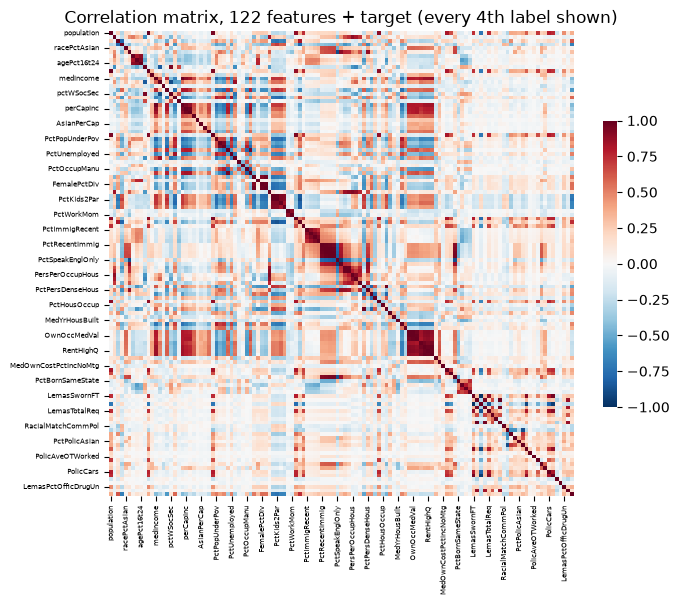

Pairs with |r| > 0.9: 58 | strongest with target: {'PctKids2Par': -0.74, 'PctIlleg': 0.74, 'PctFam2Par': -0.71, 'racePctWhite': -0.68}


In [7]:
# Question 2c
corr = crime_imp.corr()
fig, ax = plt.subplots(figsize=(7.5, 6.2))
sns.heatmap(corr, cmap="RdBu_r", vmin=-1, vmax=1, square=True, xticklabels=4,
            yticklabels=4, cbar_kws={"shrink": 0.6}, ax=ax)
ax.tick_params(labelsize=5)
ax.set_title("Correlation matrix, 122 features + target (every 4th label shown)")
plt.show()

feat_corr = corr.drop(index=TARGET, columns=TARGET).values
n_high = int((np.abs(feat_corr[np.triu_indices(122, k=1)]) > 0.9).sum())
tc = corr[TARGET].drop(TARGET)
top = tc.reindex(tc.abs().sort_values(ascending=False).index)[:4].round(2).to_dict()
print(f"Pairs with |r| > 0.9: {n_high} | strongest with target: {top}")

Large blocks of strongly correlated features (income, family structure, immigration, housing, police) mean strong collinearity, which motivates ridge, the LASSO and PCR.

In [8]:
# Question 2d
# CV = s / m is a scale-free spread measure. Features are normalized to [0, 1], so a
# tiny mean (mostly-zero count features) is what blows the CV up.
feats = crime_imp.drop(columns=TARGET)
cv_s = (feats.std(ddof=1) / feats.mean()).sort_values(ascending=False).round(3)
print(f"CV computed for all {len(cv_s)} features (full values in cv_s): "
      f"min {cv_s.min():.2f}, median {cv_s.median():.2f}, max {cv_s.max():.2f}")
print("Top 11 (used in 2e):")
print(textwrap.fill(", ".join(f"{k} {v:.2f}" for k, v in cv_s.head(11).items()), 85))

CV computed for all 122 features (full values in cv_s): min 0.06, median 0.52, max 5.45
Top 11 (used in 2e):
PctPolicAsian 5.45, NumStreet 4.41, NumInShelters 3.48, NumIlleg 2.99, NumImmig 2.90,
LemasPctOfficDrugUn 2.56, NumUnderPov 2.31, population 2.20, LemasSwornFT 2.08,
numbUrban 2.00, HousVacant 1.96


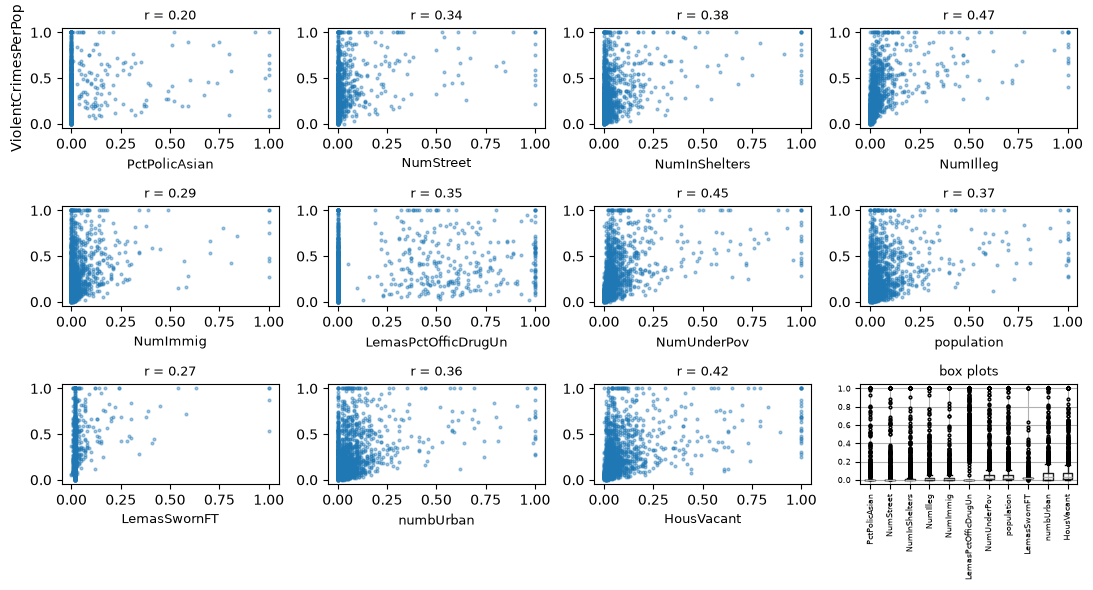

In [9]:
# Question 2e
# floor(sqrt(128)) = 11 features. Scatter = each feature vs. the target (marginal only);
# last panel = their box plots to show the skew.
top_cv = cv_s.index[:int(np.floor(np.sqrt(128)))].tolist()
fig, axes = plt.subplots(3, 4, figsize=(11, 6))
for ax, f in zip(axes.flat, top_cv):
    ax.scatter(crime_imp[f], crime_imp[TARGET], s=4, alpha=0.4)
    r = crime_imp[f].corr(crime_imp[TARGET])
    ax.set_xlabel(f, fontsize=9); ax.set_title(f"r = {r:.2f}", fontsize=9)
axes.flat[0].set_ylabel(TARGET)
crime_imp[top_cv].boxplot(ax=axes.flat[-1], rot=90, fontsize=6,
                          flierprops={"markersize": 2})
axes.flat[-1].set_title("box plots", fontsize=9)
plt.tight_layout(); plt.show()

**Can we conclude significance from the scatter plots? No.** These features (mostly counts such as NumIlleg, NumUnderPov, population) are very right-skewed (box plots: medians near 0, long tails), so the plots are dominated by a few large communities, and PctPolicAsian/LemasSwornFT are mostly the imputed median. Some show weak positive trends ($r \approx 0.4$–$0.5$), but a scatter plot only shows a marginal relationship; significance depends on the other, highly correlated features and needs a test or model, not visual inspection.

In [10]:
# Question 2f: least squares
# Test error = MSE on the 499 test rows for every model. Same 10 shuffled folds (cv2)
# are reused for all the CV choices below so the models are compared fairly
results = {}
cv2 = KFold(n_splits=10, shuffle=True, random_state=RS)
ols = LinearRegression().fit(X_train, y_train)
results["Least squares"] = mean_squared_error(y_test, ols.predict(X_test))
print(f"Least squares test MSE: {results['Least squares']:.5f}")

# Question 2g: ridge
# L2 penalty lambda*sum(beta^2) shrinks all coefficients toward 0, never exactly to 0
# Penalty depends on scale -> standardize first
# lambda picked by 10-fold CV over a log grid
ridge = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 4, 200), cv=cv2))
ridge.fit(X_train, y_train)
results["Ridge"] = mean_squared_error(y_test, ridge.predict(X_test))
print(f"Ridge: lambda = {ridge[-1].alpha_:.2f}, test MSE {results['Ridge']:.5f}")

Least squares test MSE: 0.01797
Ridge: lambda = 95.48, test MSE 0.01741


In [11]:
# Question 2h: LASSO
# L1 penalty lambda*sum(|beta|) can push coefficients exactly to 0 -> variable selection
# LassoCV tries 100 lambdas along the path and keeps the one with the lowest CV MSE.
# Footnote 4: features are already normalized to [0, 1], so standardizing should barely
# change things -- fit both versions to check.
models = {"LASSO": LassoCV(cv=cv2, random_state=RS, max_iter=50000),
          "LASSO (standardized)": make_pipeline(
              StandardScaler(), LassoCV(cv=cv2, random_state=RS, max_iter=50000))}
sel = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    results[name] = mean_squared_error(y_test, model.predict(X_test))
    lcv = model[-1] if name.endswith("(standardized)") else model
    coef = pd.Series(lcv.coef_, index=X_train.columns)
    nz = coef[coef != 0]
    sel[name] = nz.reindex(nz.abs().sort_values(ascending=False).index)
    print(f"{name}: lambda = {lcv.alpha_:.2e}, test MSE {results[name]:.5f}, "
          f"{len(sel[name])} of 122 selected")

a, b = set(sel["LASSO"].index), set(sel["LASSO (standardized)"].index)
print(f"Both fits share {len(a & b)} variables; only unstandardized: {sorted(a - b)}; "
      f"only standardized: {sorted(b - a)}")

# Selected variables (unstandardized fit) ranked by |coef|; read down each column
kept = list(sel["LASSO"].index)
n_sel = len(kept)
n_rows = int(np.ceil(n_sel / 4))
kept += [""] * (4 * n_rows - len(kept))
pd.DataFrame(np.array(kept).reshape(4, n_rows).T,
             columns=[f"rank {i * n_rows + 1}-{min((i + 1) * n_rows, n_sel)}"
                      for i in range(4)]).replace("", "-")

LASSO: lambda = 8.19e-05, test MSE 0.01769, 79 of 122 selected
LASSO (standardized): lambda = 6.19e-04, test MSE 0.01773, 76 of 122 selected
Both fits share 75 variables; only unstandardized: ['PctBSorMore', 'PctWorkMomYoungKids', 'agePct65up', 'medFamInc']; only standardized: ['PctImmigRecent']


,rank 1-20,rank 21-40,rank 41-60,rank 61-79
0,agePct12t29,PolicReqPerOffic,LandArea,blackPerCap
1,racepctblack,pctWWage,pctUrban,PctOccupManu
2,PctPersDenseHous,PctNotSpeakEnglWell,PctRecImmig10,PctPolicBlack
3,PctKids2Par,PctIlleg,NumKindsDrugsSeiz,PctPolicAsian
4,MedRent,MedRentPctHousInc,LemasGangUnitDeploy,PctEmplManu
5,PctEmploy,agePct12t21,PctYoungKids2Par,MedOwnCostPctInc
6,MalePctNevMarr,whitePerCap,PctBSorMore,racePctAsian
7,RentLowQ,LemasSwFTFieldPerPop,indianPerCap,LemasPctPolicOnPatr
8,NumStreet,MedOwnCostPctIncNoMtg,pctWFarmSelf,PopDens
9,PctPopUnderPov,NumInShelters,RacialMatchCommPol,MedYrHousBuilt


Both LASSO fits have almost the same test error and select almost the same ~2/3 of the features, as expected since the features are already normalized to [0, 1]; standardizing only slightly changes the penalty on a few borderline variables. Both beat least squares slightly.

PCR: M = 97, test MSE 0.01837


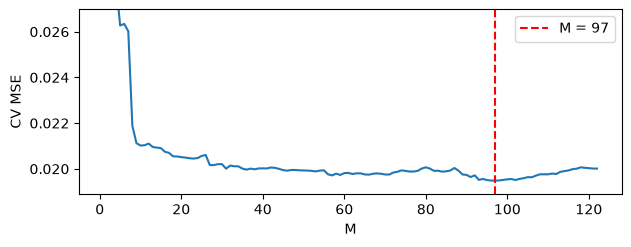

In [12]:
# Question 2i: PCR
# Standardize -> PCA -> least squares on the first M components. PCA is unsupervised (it
# never looks at y), so the top components aren't useful for y.
# Scaling + PCA sit inside the pipeline so they're refit within every CV fold.
pipe = Pipeline([("sc", StandardScaler()), ("pca", PCA()), ("ols", LinearRegression())])
pcr = GridSearchCV(pipe, {"pca__n_components": range(1, 123)}, cv=cv2,
                   scoring="neg_mean_squared_error", n_jobs=-1).fit(X_train, y_train)
M = pcr.best_params_["pca__n_components"]
results["PCR"] = mean_squared_error(y_test, pcr.predict(X_test))
print(f"PCR: M = {M}, test MSE {results['PCR']:.5f}")

cvm = -pcr.cv_results_["mean_test_score"]
fig, ax = plt.subplots(figsize=(7, 2.4))
ax.plot(range(1, 123), cvm); ax.axvline(M, color="red", ls="--", label=f"M = {M}")
ax.set_ylim(cvm.min() * 0.97, np.percentile(cvm, 97))
ax.set_xlabel("M"); ax.set_ylabel("CV MSE"); ax.legend()
plt.show()

CV error falls sharply over the first ~10 components and is then nearly flat; the chosen $M$ is large and PCR is slightly worse than least squares, since components ignore the response.

In [13]:
# Question 2j
# Boosting: fit small regression trees one after another, each one to the residuals
# (gradient of squared error) of the current model, added with a learning rate.
# reg_alpha = L1 penalty on leaf weights (soft-thresholds them, like LASSO on betas).
# reg_lambda = 0 so L1 is the only penalty; alpha chosen with the same 10-fold CV.
# Note: needs `pip install xgboost`.
from xgboost import XGBRegressor

xgb = XGBRegressor(objective="reg:squarederror", n_estimators=500, learning_rate=0.05,
                   max_depth=3, subsample=0.8, colsample_bytree=0.5, reg_lambda=0.0,
                   random_state=RS, n_jobs=-1)
alpha_grid = {"reg_alpha": [0, 0.001, 0.01, 0.05, 0.1, 0.5, 1, 2, 5, 10]}
xgb_cv = GridSearchCV(xgb, alpha_grid, cv=cv2, scoring="neg_mean_squared_error")
xgb_cv.fit(X_train, y_train)
results["XGBoost (L1)"] = mean_squared_error(y_test, xgb_cv.predict(X_test))
print(f"Chosen alpha = {xgb_cv.best_params_['reg_alpha']}, "
      f"CV MSE {-xgb_cv.best_score_:.5f}, test MSE {results['XGBoost (L1)']:.5f}")

Chosen alpha = 1, CV MSE 0.01882, test MSE 0.01584


**Discussion of 2(j).** CV chose $\alpha = 1$ (CV MSE 0.01882), and the boosted tree has the lowest test MSE of all models, 0.01584: about 9% below ridge (0.01741) and 12% below least squares (0.01797). $\alpha = 1$ mostly shrinks or zeroes leaves with few samples or small residual sums. It is a mild extra penalty on top of the learning rate, shallow trees and subsampling. Unlike the linear models, the trees can model non-linear effects and interactions (e.g. the skewed count features from 2(e)), which likely explains the gain.

In [14]:
# Summary of test errors
pd.Series(results, name="test MSE").sort_values().round(5).to_frame()

,test MSE
XGBoost (L1),0.01584
Ridge,0.01741
LASSO,0.01769
LASSO (standardized),0.01773
Least squares,0.01797
PCR,0.01837


XGBoost has the lowest test error; ridge and the LASSO improve slightly on least squares (122 collinear features), and PCR is slightly worse. Overall the differences are modest (test RMSE 0.126–0.136 on a [0, 1] response).